# LAB 09

## Student Information
- **Name:** Abdul Sami
- **Student ID:** 023-24-0211
- **Section:** G
- **GitHub:** https://github.com/abdulsami911/Machine_learning_Practical
- **Kaggle:** https://www.kaggle.com/abdulsami911
- **Dataset:** healthcare-dataset-stroke-data
- **Dataset Source:** https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

## Part 0 — Setup and the Data

In [ ]:
%pip install imbalanced-learn
%pip install matplotlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_val_predict, learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

SEED = 42

print("Libraries imported successfully!")

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Libraries imported successfully!


In [ ]:
# In Colab: from google.colab import files; files.upload()   (upload the CSV first)
CSV = "healthcare-dataset-stroke-data_1.csv"
df = pd.read_csv(CSV)

print("Shape:", df.shape)
print("\nColumns with missing values:")
print(df.isna().sum()[lambda s: s > 0])
print("\nGender value counts:")
print(df["gender"].value_counts())
vc = df["stroke"].value_counts()
print("\nStroke counts:")
for k in (1, 0):
    print(f"  stroke = {k}: {vc[k]:5d}  ({vc[k] / len(df):.2%})")

Shape: (5110, 12)

Columns with missing values:
bmi    201
dtype: int64

Gender value counts:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke counts:
  stroke = 1:   249  (4.87%)
  stroke = 0:  4861  (95.13%)


**Interpretation.** The file has 5,110 patients and 12 columns. Only `bmi` has missing values (201 rows, 3.9%), so a single median imputation is enough. `gender` has 2,994 Female, 2,115 Male and exactly **1 "Other"** row, which cannot be learned from and cannot be split across train and test, so it is removed in the next cell. The target is very rare: 249 strokes (4.87%) versus 4,861 non-strokes (95.13%).

In [ ]:
# 3. Clean: drop identifier, drop the 1-row 'Other' gender, one-hot encode text columns
df = df.drop(columns="id")
df = df[df["gender"] != "Other"].reset_index(drop=True)
df_enc = pd.get_dummies(df, drop_first=True, dtype=int)
y = df_enc.pop("stroke")
X = df_enc
print("Features after encoding:", X.shape[1])
print(list(X.columns))

# 4. Split 80/20 stratified; impute with TRAIN median; scaled copy fitted on TRAIN only
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

train_median = X_train.median()          # learned from TRAIN only
X_train = X_train.fillna(train_median)
X_test = X_test.fillna(train_median)

scaler = StandardScaler().fit(X_train)   # fitted on TRAIN only
Xs_train = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
Xs_test = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# 5. Stroke counts per split
print(f"\nTrain: {len(y_train)} rows, strokes = {y_train.sum()} ({y_train.mean():.2%})")
print(f"Test : {len(y_test)} rows, strokes = {y_test.sum()} ({y_test.mean():.2%})")

Features after encoding: 15
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Male', 'ever_married_Yes', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']

Train: 4087 rows, strokes = 199 (4.87%)
Test : 1022 rows, strokes = 50 (4.89%)


**Interpretation.** After dropping `id` and the single "Other" row we have 5,109 patients and 15 features after one-hot encoding. The stratified split gives 4,087 train rows with **199 strokes (4.87%)** and 1,022 test rows with **50 strokes (4.89%)**; the median used for `bmi` and the scaler were learned from the train rows only.

**Question (a) — how imbalanced is the data? Why `stratify=y`?**
Roughly 1 stroke per 20 patients (about 19.5 : 1). `stratify=y` forces train and test to keep the same 4.9% stroke rate. Without it, a random split could put, say, 30 or 70 strokes in the test set (or very few), so the test metrics would depend on luck. Even now the test set has only 50 strokes, so every stroke patient is worth 2 points of recall (1/50) and all test metrics are noisy; with fewer strokes a single patient could swing recall by 5-10 points, or the test set could contain almost no positives, making recall/PR AUC meaningless.

## Part 1 — The Accuracy Trap

                     Accuracy  Precision  Recall        F1   ROC AUC    PR AUC
Dummy (always 0)     0.951076        0.0    0.00  0.000000  0.500000  0.048924
Logistic Regression  0.952055        1.0    0.02  0.039216  0.839424  0.269219


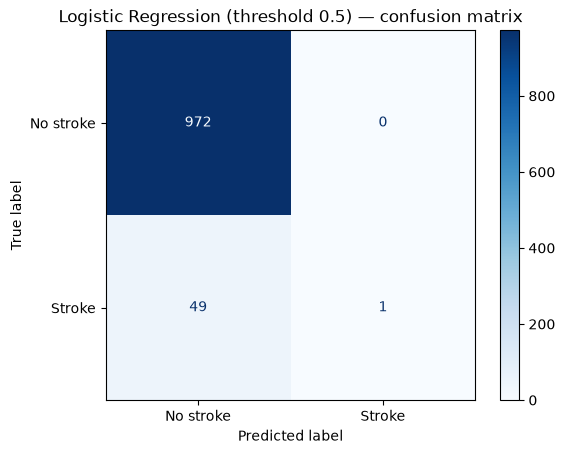

TN=972  FP=0  FN=49  TP=1


In [ ]:
def evaluate(model, Xtr, ytr, Xte, yte, threshold=None, fit=True):
    """Fit (optionally) and return the six metrics on the test set.
    If threshold is given, class labels use proba >= threshold instead of 0.5."""
    if fit:
        model.fit(Xtr, ytr)
    proba = model.predict_proba(Xte)[:, 1]
    pred = model.predict(Xte) if threshold is None else (proba >= threshold).astype(int)
    return {"Accuracy": accuracy_score(yte, pred),
            "Precision": precision_score(yte, pred, zero_division=0),
            "Recall": recall_score(yte, pred),
            "F1": f1_score(yte, pred, zero_division=0),
            "ROC AUC": roc_auc_score(yte, proba),
            "PR AUC": average_precision_score(yte, proba)}

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
r_dummy = evaluate(dummy, X_train, y_train, X_test, y_test, fit=False)

lr_default = LogisticRegression(max_iter=1000, random_state=SEED)
r_lr = evaluate(lr_default, Xs_train, y_train, Xs_test, y_test)

print(pd.DataFrame({"Dummy (always 0)": r_dummy, "Logistic Regression": r_lr}).T)

ConfusionMatrixDisplay.from_predictions(y_test, lr_default.predict(Xs_test),
                                        display_labels=["No stroke", "Stroke"], cmap="Blues")
plt.title("Logistic Regression (threshold 0.5) — confusion matrix"); plt.grid(False); plt.show()
tn, fp, fn, tp = confusion_matrix(y_test, lr_default.predict(Xs_test)).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

**Interpretation.** The "always predict no stroke" baseline reaches **95.11% accuracy** with zero knowledge (Recall 0, ROC AUC 0.5). Logistic Regression reaches **95.21%**, only 0.1 percentage points (one patient) better. Its confusion matrix is TN=972, FP=0, FN=49, TP=1: it flagged a single patient as high-risk and was right, so Precision is 1.00 but that rests on one prediction and is meaningless. Recall is 0.020 and F1 0.039. Yet ROC AUC is 0.839 and PR AUC 0.269, so the model *has* learned something useful that accuracy and the 0.5 cut-off hide.

**Question (a).** Accuracy is almost identical (95.21% vs 95.11%), so accuracy cannot tell a useless model from a real one when 95% of patients are healthy. Logistic Regression at its default threshold behaves essentially like the baseline: it says "no stroke" to nearly everyone.

**Question (b).** A false negative is a patient who will have a stroke but is told they are fine, so they get no prevention or follow-up; here 49 of 50 strokes are missed. In a screening setting this is the costly error. Instead of accuracy we should trust **Recall** (how many strokes we catch), **PR AUC** and **ROC AUC** (quality of the ranking, independent of the threshold), and F1/precision only together with recall.

## Part 2 — Underfitting, Overfitting, Bias and Variance
From here on **ROC AUC** is the CV score.

max_depth  Train AUC   CV AUC
        1   0.717126 0.731666
        2   0.820772 0.816755
        3   0.837524 0.816109
        4   0.857995 0.818040
        5   0.875836 0.792089
        6   0.902562 0.758513
        7   0.927578 0.738470
        8   0.949412 0.713760
        9   0.967792 0.681188
       10   0.980835 0.641388
       11   0.990997 0.610807
       12   0.995874 0.612583
       13   0.998498 0.595539
       14   0.999575 0.588883
       15   0.999950 0.577850
     None   1.000000 0.564415

Best depth by CV AUC: 4  (CV AUC = 0.8180, Train AUC = 0.8580)


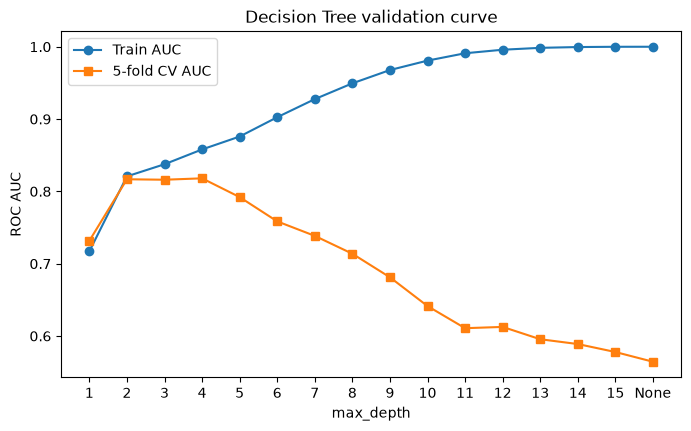

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
depths = list(range(1, 16)) + [None]
rows = []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    cv_auc = cross_val_score(tree, X_train, y_train, cv=skf, scoring="roc_auc").mean()
    tree.fit(X_train, y_train)
    tr_auc = roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1])
    rows.append({"max_depth": "None" if d is None else d, "Train AUC": tr_auc, "CV AUC": cv_auc})
val_df = pd.DataFrame(rows)
print(val_df.to_string(index=False))

best = val_df.loc[val_df["CV AUC"].idxmax()]
print(f"\nBest depth by CV AUC: {best['max_depth']}  (CV AUC = {best['CV AUC']:.4f}, Train AUC = {best['Train AUC']:.4f})")

x = np.arange(len(val_df))
plt.figure(figsize=(8, 4.5))
plt.plot(x, val_df["Train AUC"], "o-", label="Train AUC")
plt.plot(x, val_df["CV AUC"], "s-", label="5-fold CV AUC")
plt.xticks(x, val_df["max_depth"].astype(str))
plt.xlabel("max_depth"); plt.ylabel("ROC AUC"); plt.title("Decision Tree validation curve")
plt.legend(); plt.show()

**Interpretation.** Train AUC rises monotonically with depth (0.717 at depth 1 → 1.000 for an unlimited tree) while CV AUC peaks early (**0.818 at depth 4**) and then falls to 0.564 for `max_depth=None`, barely better than guessing.

**Question (a).**
- **Underfitting (high bias):** depth 1, train AUC 0.717 and CV AUC 0.732; both are low, the stump is too simple.
- **Good zone:** depths 2-4, CV AUC about 0.816-0.818 with a small gap between train and CV (depth 3: train 0.838, CV 0.816).
- **Overfitting (high variance):** from depth ~6 onward, e.g. depth 10: train 0.981 but CV 0.641; `None`: train 1.000 but CV 0.564.

The best depth by CV is 4 (0.8180), but depths 2, 3 and 4 differ by less than 0.002, which is within noise. I would choose **depth 3**: same CV AUC (0.816), simpler, and a smaller train-CV gap (0.021 vs 0.040 at depth 4).

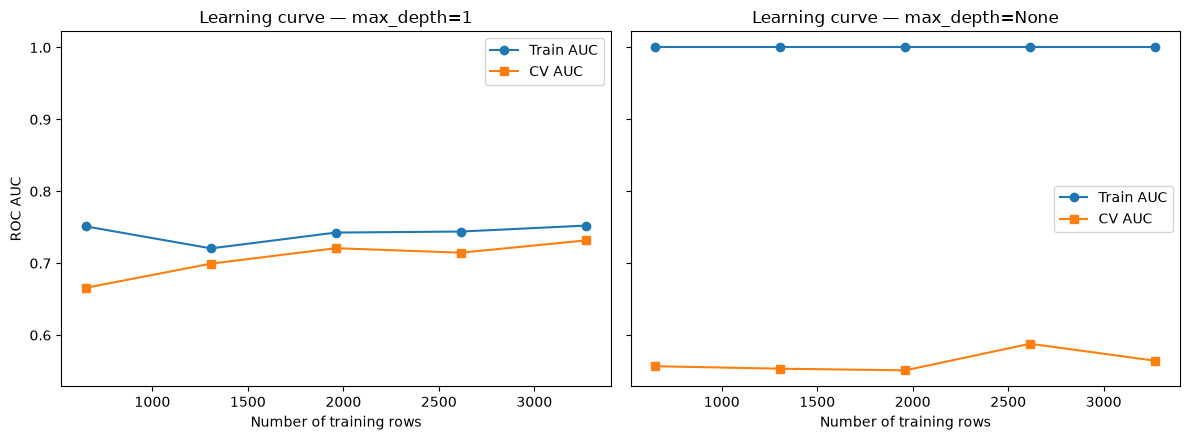

max_depth=1
 train rows  Train AUC   CV AUC
        653   0.751155 0.665899
       1307   0.720623 0.699413
       1961   0.742615 0.720885
       2615   0.744020 0.714600
       3269   0.752313 0.731666

max_depth=None
 train rows  Train AUC   CV AUC
        653        1.0 0.556770
       1307        1.0 0.553315
       1961        1.0 0.551009
       2615        1.0 0.587992
       3269        1.0 0.564415



In [ ]:
sizes = np.linspace(0.2, 1.0, 5)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
lc_tables = {}
for ax, d in zip(axes, [1, None]):
    ts, trs, vas = learning_curve(DecisionTreeClassifier(max_depth=d, random_state=SEED),
                                  X_train, y_train, train_sizes=sizes, cv=skf,
                                  scoring="roc_auc", shuffle=True, random_state=SEED)
    tr_m, va_m = trs.mean(axis=1), vas.mean(axis=1)
    lc_tables[d] = pd.DataFrame({"train rows": ts, "Train AUC": tr_m, "CV AUC": va_m})
    ax.plot(ts, tr_m, "o-", label="Train AUC"); ax.plot(ts, va_m, "s-", label="CV AUC")
    ax.set_title(f"Learning curve — max_depth={d}")
    ax.set_xlabel("Number of training rows"); ax.legend()
axes[0].set_ylabel("ROC AUC"); plt.tight_layout(); plt.show()
for d, t in lc_tables.items():
    print(f"max_depth={d}"); print(t.to_string(index=False)); print()

**Interpretation.**
- **max_depth=1:** train AUC stays around 0.72-0.75 and CV AUC climbs from 0.666 (653 rows) to 0.732 (3,269 rows); both curves meet at a low level (~0.73-0.75).
- **max_depth=None:** train AUC is exactly 1.000 at every size, CV AUC stays flat at 0.55-0.59 (0.557 → 0.564), a huge gap of about 0.44 that does not close.

**Question (b).** *High bias* = both curves are low and close together (the stump). *High variance* = train score far above CV score with a large gap (the unlimited tree). More rows will **not** fix high bias: the stump's curves have already flattened near 0.73-0.75, its limit is the model, not the data; we need a richer model. For high variance more data can in principle shrink the gap, but here the CV curve is essentially flat even from 653 to 3,269 rows, so adding rows is not an efficient fix; limiting depth or averaging many trees (Random Forest) is.

In [ ]:
B = 40
rng = np.random.default_rng(SEED)
var_rows = []
for d in [1, 3, None]:
    probs = np.zeros((B, len(X_test)))
    single_aucs = []
    for b in range(B):
        idx = rng.choice(len(X_train), len(X_train), replace=True)
        t = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_train.iloc[idx], y_train.iloc[idx])
        probs[b] = t.predict_proba(X_test)[:, 1]
        single_aucs.append(roc_auc_score(y_test, probs[b]))
    var_rows.append({"max_depth": "None" if d is None else d,
                     "Mean variance of predicted prob": probs.var(axis=0).mean(),
                     "Mean AUC of single trees": np.mean(single_aucs),
                     "Std of single-tree AUC": np.std(single_aucs),
                     "AUC of averaged prediction": roc_auc_score(y_test, probs.mean(axis=0))})
var_df = pd.DataFrame(var_rows)
print(var_df.to_string(index=False))

max_depth  Mean variance of predicted prob  Mean AUC of single trees  Std of single-tree AUC  AUC of averaged prediction
        1                         0.000680                  0.762342                0.016068                    0.813169
        3                         0.001668                  0.796440                0.011681                    0.834290
     None                         0.041972                  0.555248                0.026098                    0.756595


**Interpretation.**

| max_depth | mean variance of predicted prob. | mean single-tree AUC | AUC of averaged prediction |
|---|---|---|---|
| 1 | 0.0007 | 0.762 | 0.813 |
| 3 | 0.0017 | 0.796 | 0.834 |
| None | **0.0420** | 0.555 | 0.757 |

**Question (c).** Variance grows with depth: the unlimited tree's prediction variance is about 25x that of depth 3 and about 60x that of depth 1, because it can build a different set of leaves from every bootstrap sample. Its single-tree AUC (0.555) is near random and also varies most from tree to tree (std 0.026). Averaging 40 trees helps every depth, but helps the high-variance tree most: AUC jumps from 0.555 to **0.757 (+0.20)**, versus +0.038 for depth 3 and +0.051 for depth 1. This is exactly the idea of Random Forest (Lab 4): train many deep, low-bias, high-variance trees on bootstrap samples and average them so the variance cancels. Note that averaged deep trees (0.757) are still worse than an averaged shallow tree (0.834); the forest in Part 3 also uses `min_samples_leaf=5` and random feature subsets to reduce variance further.

**Question (d).** Expected error = bias² + variance + noise. Simple models have high bias and low variance; complex models have low bias and high variance; we want the depth where the sum is smallest. **Depth 1** sits on the high-bias side (low variance 0.0007, low AUC 0.76). **Depth 3** is close to the sweet spot (variance 0.0017, best single-tree AUC 0.796). **Depth None** has almost zero bias on the training data (train AUC 1.0) but the highest variance (0.042) and the worst generalisation.

## Part 3 — ROC, AUC, Precision-Recall and Thresholds

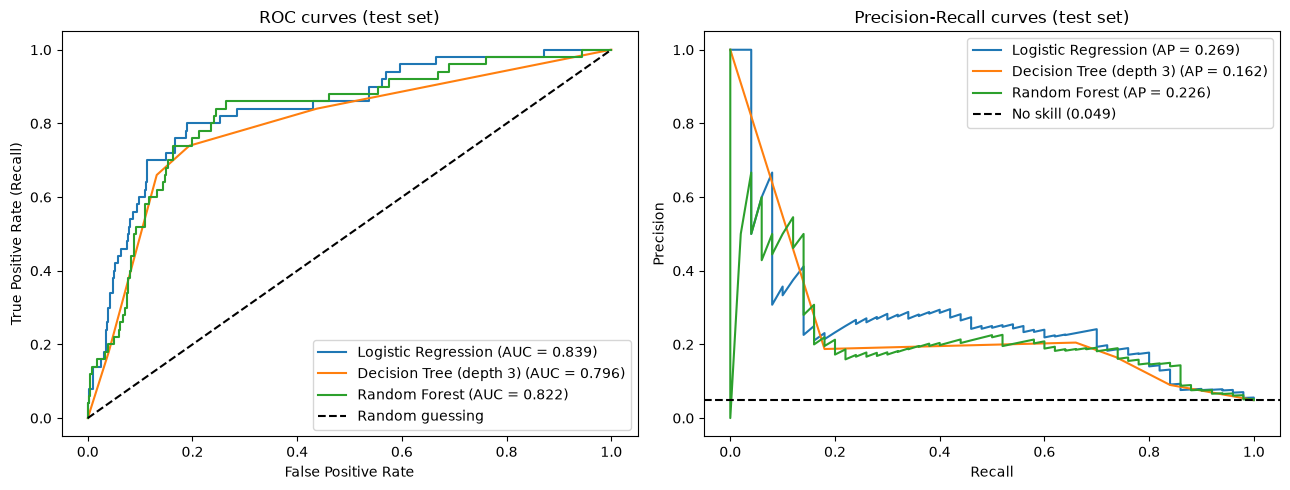

No-skill level (stroke rate in test) = 0.0489


,ROC AUC,Average precision (PR AUC),AP / no-skill
Logistic Regression,0.839424,0.269219,5.502846
Decision Tree (depth 3),0.795576,0.162061,3.312536
Random Forest,0.822449,0.225524,4.609704


In [ ]:
models3 = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=SEED), Xs_train, Xs_test),
    "Decision Tree (depth 3)": (DecisionTreeClassifier(max_depth=3, random_state=SEED), X_train, X_test),
    "Random Forest": (RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1), X_train, X_test),
}
test_proba = {}
for name, (m, Xtr, Xte) in models3.items():
    m.fit(Xtr, y_train)
    test_proba[name] = m.predict_proba(Xte)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random guessing")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].set_title("ROC curves (test set)"); axes[0].legend(loc="lower right")

for name, p in test_proba.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, label=f"{name} (AP = {average_precision_score(y_test, p):.3f})")
no_skill = y_test.mean()
axes[1].axhline(no_skill, color="k", ls="--", label=f"No skill ({no_skill:.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curves (test set)"); axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

curve_tab = pd.DataFrame({
    "ROC AUC": {n: roc_auc_score(y_test, p) for n, p in test_proba.items()},
    "Average precision (PR AUC)": {n: average_precision_score(y_test, p) for n, p in test_proba.items()}})
curve_tab["AP / no-skill"] = curve_tab["Average precision (PR AUC)"] / no_skill
print(f"No-skill level (stroke rate in test) = {no_skill:.4f}")
curve_tab

**Interpretation.**

| Model | ROC AUC | Average precision | AP / no-skill |
|---|---|---|---|
| Logistic Regression | **0.839** | **0.269** | 5.5x |
| Random Forest | 0.822 | 0.226 | 4.6x |
| Decision Tree (depth 3) | 0.796 | 0.162 | 3.3x |

All three models are clearly above the random diagonal. Logistic Regression is best on both curves, the Random Forest second, the shallow tree last (its stair-step curve has only a few distinct scores). On this small, mostly linear signal (age, glucose, hypertension, heart disease) the simple, low-variance linear model wins.

Chosen threshold (from TRAIN out-of-fold): 0.0509
  OOF recall = 0.804, OOF precision = 0.136

TEST at threshold 0.0509:
  Recall = 0.820, Precision = 0.135
  Confusion matrix: TN=710 FP=262 FN=9 TP=41
  Patients flagged = 303 out of 1022 (29.6%); false alarms = 262


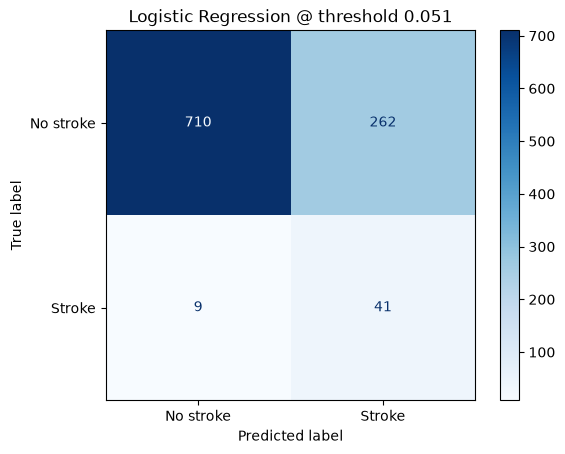

In [ ]:
# Out-of-fold probabilities on TRAIN only. The scaler sits inside the pipeline so each
# fold fits it on its own training part (no leakage from the validation fold).
lr_pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
oof = cross_val_predict(lr_pipe, X_train, y_train, cv=skf, method="predict_proba")[:, 1]

fpr, tpr, thr = roc_curve(y_train, oof, drop_intermediate=False)
thr_choice = thr[np.argmax(tpr >= 0.80)]            # highest threshold with recall >= 0.80
oof_recall = recall_score(y_train, oof >= thr_choice)
oof_prec = precision_score(y_train, oof >= thr_choice)
print(f"Chosen threshold (from TRAIN out-of-fold): {thr_choice:.4f}")
print(f"  OOF recall = {oof_recall:.3f}, OOF precision = {oof_prec:.3f}")

p_lr = test_proba["Logistic Regression"]
pred_thr = (p_lr >= thr_choice).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_thr).ravel()
print(f"\nTEST at threshold {thr_choice:.4f}:")
print(f"  Recall = {recall_score(y_test, pred_thr):.3f}, Precision = {precision_score(y_test, pred_thr):.3f}")
print(f"  Confusion matrix: TN={tn} FP={fp} FN={fn} TP={tp}")
print(f"  Patients flagged = {fp + tp} out of {len(y_test)} ({(fp + tp) / len(y_test):.1%}); false alarms = {fp}")
ConfusionMatrixDisplay.from_predictions(y_test, pred_thr, display_labels=["No stroke", "Stroke"], cmap="Blues")
plt.title(f"Logistic Regression @ threshold {thr_choice:.3f}"); plt.grid(False); plt.show()

**Interpretation.** On the training out-of-fold probabilities the highest threshold with recall >= 0.80 is **0.0509**, which gives OOF recall 0.804 and precision 0.136. Applying it unchanged to the test set gives **recall 0.820 (41 of 50 strokes caught)** and precision 0.135. Confusion matrix: TN=710, FP=262, FN=9, TP=41. **303 of 1,022 patients (29.6%) are flagged, 262 of them false alarms.** The test recall is close to the OOF estimate, so choosing the threshold on training data only worked and was honest.

**Question (a).** ROC AUC measures only the **ranking**: AUC 0.839 means a random stroke patient gets a higher risk score than a random healthy patient about 84% of the time. It is computed over *all* thresholds. Recall, in contrast, is computed at one threshold: 0.5. Because only 4.9% of patients have strokes, even high-risk patients get predicted probabilities well below 0.5 (the useful cut-off is near 0.05, close to the base rate), so almost nobody crosses 0.5 and recall is 0.02. The model ranks well but the 0.5 threshold is in the wrong place.

**Question (b).** **Precision-Recall** is more informative here. The no-skill line is the stroke rate, 0.049. The ROC plot looks comfortable (AUC 0.84) because the false-positive *rate* divides by 972 healthy patients, so 262 false alarms is only a 27% FPR. The PR curve shows what the hospital actually experiences: LR's average precision is 0.269, only 5.5x the no-skill 0.049, and precision falls to about 0.13 at high recall. PR separates the models more too (AP 0.269 / 0.226 / 0.162 vs ROC 0.839 / 0.822 / 0.796).

**Question (c).** The price: 303 patients (30% of those screened) are flagged to catch 41 strokes, so about 7.4 flagged patients per true stroke; 262 healthy people get false alarms (follow-up tests, anxiety, cost). *Acceptable:* the follow-up (blood pressure, glucose, a doctor visit) is cheap and a missed stroke can be fatal or disabling, so going from 1 caught stroke to 41 and from 49 misses to 9 is worth it. *Not acceptable:* if follow-up is expensive or invasive, or clinics cannot handle 30% of patients flagged, 87% false alarms will overload the system and erode trust. My view: acceptable as a first-stage screen, because a cheap second test can filter the 262 false alarms.

## Part 4 — Undersampling, Oversampling and SMOTE
Resampling is applied to the **training set only**; the test set is never touched. Logistic Regression uses the scaled data, Random Forest the original data.

In [ ]:
def make_model(name, class_weight=None):
    if name == "LogReg":
        return LogisticRegression(max_iter=1000, class_weight=class_weight, random_state=SEED)
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight=class_weight,
                                  random_state=SEED, n_jobs=-1)

def run_method(name, Xtr, ytr, Xte, yte, method):
    cw = "balanced" if method == "class_weight='balanced'" else None
    if method == "undersampling":
        Xr, yr = RandomUnderSampler(random_state=SEED).fit_resample(Xtr, ytr)
    elif method == "oversampling":
        Xr, yr = RandomOverSampler(random_state=SEED).fit_resample(Xtr, ytr)
    elif method == "SMOTE":
        Xr, yr = SMOTE(random_state=SEED).fit_resample(Xtr, ytr)
    else:
        Xr, yr = Xtr, ytr
    res = evaluate(make_model(name, cw), Xr, yr, Xte, yte)
    return {"Train rows": len(yr), "Train strokes": int(np.sum(yr)),
            **{k: res[k] for k in ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]}}

methods = ["no resampling", "class_weight='balanced'", "undersampling", "oversampling", "SMOTE"]
tab = {}
for name, (Xtr, Xte) in {"LogReg": (Xs_train, Xs_test), "RandomForest": (X_train, X_test)}.items():
    for m in methods:
        tab[f"{name} | {m}"] = run_method(name, Xtr, y_train, Xte, y_test, m)
res41 = pd.DataFrame(tab).T
res41[["Train rows", "Train strokes"]] = res41[["Train rows", "Train strokes"]].astype(int)
res41

,Train rows,Train strokes,Precision,Recall,F1,ROC AUC,PR AUC
LogReg | no resampling,4087,199,1.000000,0.02,0.039216,0.839424,0.269219
LogReg | class_weight='balanced',4087,199,0.134680,0.80,0.230548,0.839547,0.259548
LogReg | undersampling,398,199,0.124620,0.82,0.216359,0.835206,0.233816
LogReg | oversampling,7776,3888,0.133333,0.80,0.228571,0.838457,0.264559
LogReg | SMOTE,7776,3888,0.133779,0.80,0.229226,0.840638,0.287624
RandomForest | no resampling,4087,199,0.000000,0.00,0.000000,0.822449,0.225524
RandomForest | class_weight='balanced',4087,199,0.189474,0.72,0.300000,0.815041,0.198692
RandomForest | undersampling,398,199,0.105000,0.84,0.186667,0.820309,0.202954
RandomForest | oversampling,7776,3888,0.188235,0.32,0.237037,0.811091,0.190593
RandomForest | SMOTE,7776,3888,0.126582,0.20,0.155039,0.766831,0.118651


**Interpretation.** (Test set, 50 strokes, so differences of a few thousandths are noise.)

**Question (a) — Logistic Regression.** *What changed:* the decision threshold behaviour. Recall jumps from 0.020 (no resampling) to 0.80-0.82 with every method (balanced weights 0.80, undersampling 0.82, oversampling 0.80, SMOTE 0.80); Precision drops from the meaningless 1.00 (one prediction) to 0.12-0.135, and F1 rises from 0.039 to about 0.22-0.23. *What did NOT change:* the quality of the ranking: ROC AUC stays between 0.835 and 0.841 (0.8394 none, 0.8395 balanced, 0.8352 undersampling, 0.8385 oversampling, 0.8406 SMOTE) and PR AUC between 0.234 and 0.288. Reason: LR is a rigid linear model, so rebalancing mostly shifts the intercept (the probability scale) so that stroke probabilities are no longer squeezed under 0.5; the order of patients hardly changes. Undersampling is slightly worse (ROC 0.835, PR 0.234) because it throws away 3,688 healthy rows (4,087 → 398 rows). Notice that `class_weight='balanced'` gives practically the same result as oversampling and SMOTE without changing the data.

**Question (b) — Random Forest.** No, it behaved very differently. With no resampling the forest predicts **no strokes at all** (Recall 0, Precision 0). Class weights give recall 0.30, oversampling 0.32, undersampling 0.84 (but precision only 0.105), and **SMOTE makes the ranking worse**: ROC AUC falls from 0.822 to 0.767 and PR AUC from 0.226 to 0.119, recall only 0.20. Difference: for LR resampling only moves the threshold; for RF it changes what the trees learn. Possible reason: oversampling copies each of the 199 strokes ~19.5 times, so the trees (with `min_samples_leaf=5`) can build leaves out of exact copies and memorise them (overfitting, ROC 0.811); SMOTE fills the space between strokes with synthetic points, and since the Random Forest uses unscaled features and SMOTE works on distances dominated by glucose, age and bmi, these synthetic points can land in regions of healthy patients and blur the boundary. Undersampling is the only method that gives a high-recall forest, at the price of using just 398 rows.

In [ ]:
# WRONG ORDER: SMOTE on ALL data (train + test together), THEN split
X_all = pd.concat([X_train, X_test]); y_all = pd.concat([y_train, y_test])
X_sm, y_sm = SMOTE(random_state=SEED).fit_resample(X_all, y_all)
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(X_sm, y_sm, test_size=0.20, stratify=y_sm, random_state=SEED)
res_wrong = evaluate(make_model("RF"), Xw_tr, yw_tr, Xw_te, yw_te)

res_right = res41.loc["RandomForest | SMOTE", ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]]
cmp42 = pd.DataFrame({
    "RF + SMOTE after split (correct)": res_right,
    "RF + SMOTE before split (WRONG)": pd.Series({k: res_wrong[k] for k in res_right.index})}).T
print(f"Wrong-order test set: {len(yw_te)} rows, strokes = {int(yw_te.sum())} ({yw_te.mean():.0%});"
      f"  correct test set: {len(y_test)} rows, strokes = {int(y_test.sum())} ({y_test.mean():.1%})")
cmp42

Wrong-order test set: 1944 rows, strokes = 972 (50%);  correct test set: 1022 rows, strokes = 50 (4.9%)


,Precision,Recall,F1,ROC AUC,PR AUC
RF + SMOTE after split (correct),0.126582,0.200000,0.155039,0.766831,0.118651
RF + SMOTE before split (WRONG),0.909360,0.949588,0.929039,0.982023,0.981263


**Interpretation.**

| Random Forest | Precision | Recall | F1 | ROC AUC | PR AUC |
|---|---|---|---|---|---|
| SMOTE after split (correct) | 0.127 | 0.200 | 0.155 | 0.767 | 0.119 |
| SMOTE before split (WRONG) | 0.909 | 0.950 | 0.929 | 0.982 | 0.981 |

**Question (c).** The wrong-order numbers look spectacular (ROC AUC 0.982, recall 0.95) but are fake. SMOTE creates each synthetic stroke by interpolating between a real stroke patient and one of its nearest stroke neighbours. If SMOTE runs before the split, the real patients and the synthetic patients built from them are shuffled together: a synthetic point that lands in the test set has its "parents" in the training set (and vice versa, a real test patient is used to create training rows). The forest is therefore tested on near-copies of what it trained on, i.e. **information leaks from the real/test patients into training through the synthetic rows**. In addition, the test set is now 50% strokes (972 of 1,944 rows) instead of 4.9%, so precision and PR AUC are inflated by the prevalence and are not comparable with the real hospital. The correct result (ROC AUC 0.767, recall 0.20) is the honest one: SMOTE must only touch the training data, after the split.

**Question (d).** I would pick **`class_weight='balanced'` with Logistic Regression** (or, equivalently, keeping the plain model and tuning the threshold from training out-of-fold probabilities). It is one argument, creates no synthetic patients, keeps all 4,087 training rows, trains quickly and gives recall 0.80 at F1 0.231 and ROC AUC 0.840, the same as SMOTE (recall 0.80, F1 0.229, ROC AUC 0.841). Oversampling and SMOTE double the training set to 7,776 rows for no gain; undersampling throws away 90% of the data and was slightly worse (ROC 0.835); and SMOTE hurt the Random Forest and (see Part 5) is risky with noisy labels.

## Part 5 — Noisy Data
We damage the **training** data on purpose and measure the test ROC AUC (test set untouched).

               LogReg  Tree d=3  Tree d=None  RandomForest
label noise                                               
0.00         0.839424  0.795576     0.579650      0.822449
0.05         0.825453  0.795905     0.548605      0.797078
0.10         0.819556  0.799177     0.540062      0.762852
0.20         0.787107  0.766780     0.528041      0.711342


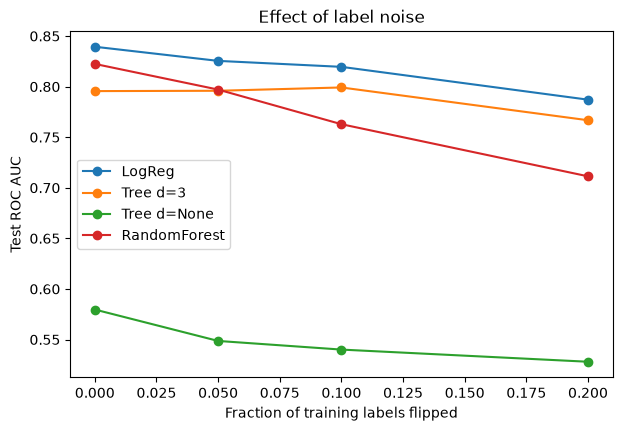

In [ ]:
def flip_labels(y, frac, rng):
    y = np.asarray(y).copy()
    n = int(round(frac * len(y)))
    idx = rng.choice(len(y), n, replace=False)
    y[idx] = 1 - y[idx]
    return y

factories = {
    "LogReg": lambda: LogisticRegression(max_iter=1000, random_state=SEED),
    "Tree d=3": lambda: DecisionTreeClassifier(max_depth=3, random_state=SEED),
    "Tree d=None": lambda: DecisionTreeClassifier(max_depth=None, random_state=SEED),
    "RandomForest": lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
}
data_for = {"LogReg": (Xs_train, Xs_test)}
for k in list(factories)[1:]:
    data_for[k] = (X_train, X_test)

fracs = [0, 0.05, 0.10, 0.20]
lab_rows = {}
for f in fracs:
    reps = 1 if f == 0 else 5
    scores = {k: [] for k in factories}
    for r in range(reps):
        rng = np.random.default_rng(SEED + 100 * r + int(f * 1000))
        yn = flip_labels(y_train, f, rng)
        for k, mk in factories.items():
            Xtr, Xte = data_for[k]
            m = mk().fit(Xtr, yn)
            scores[k].append(roc_auc_score(y_test, m.predict_proba(Xte)[:, 1]))
    lab_rows[f] = {k: np.mean(v) for k, v in scores.items()}
label_df = pd.DataFrame(lab_rows).T
label_df.index.name = "label noise"
print(label_df)

label_df.plot(marker="o", figsize=(7, 4.5))
plt.xlabel("Fraction of training labels flipped"); plt.ylabel("Test ROC AUC")
plt.title("Effect of label noise"); plt.show()

**Interpretation.** Test ROC AUC (average of 5 random flips, 1 for 0%):

| flipped | LogReg | Tree d=3 | Tree d=None | RandomForest |
|---|---|---|---|---|
| 0% | 0.839 | 0.796 | 0.580 | 0.822 |
| 5% | 0.826 | 0.796 | 0.549 | 0.797 |
| 10% | 0.820 | 0.799 | 0.540 | 0.763 |
| 20% | 0.787 | 0.767 | 0.528 | 0.711 |

Label noise lowers every model, but at very different speeds. (Flipping labels at random turns mostly healthy patients into "strokes", because there are 20x more of them, so at 20% the training set contains about 900 "strokes" instead of 199.)

                       LogReg  Tree d=3  Tree d=None  RandomForest
feature noise level                                               
0.0                  0.839424  0.795576     0.579650      0.822449
0.5                  0.833226  0.807412     0.559000      0.812576
1.0                  0.811288  0.779570     0.525630      0.786802
2.0                  0.772185  0.695807     0.515276      0.722963


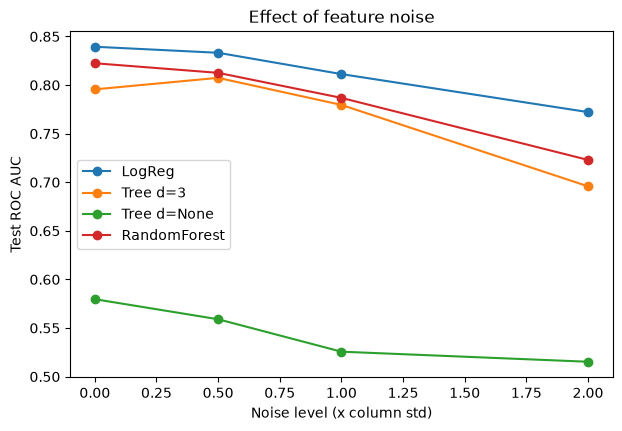

In [ ]:
def add_feature_noise(Xdf, cols, level, rng, stds):
    Xn = Xdf.copy()
    for c in cols:
        Xn[c] = Xn[c] + rng.normal(size=len(Xn)) * stds[c] * level
    return Xn

noisy_cols = ["age", "avg_glucose_level", "bmi"]
col_std = X_train[noisy_cols].std()          # std of the clean TRAIN columns
levels = [0, 0.5, 1, 2]
feat_rows = {}
for lv in levels:
    reps = 1 if lv == 0 else 5
    scores = {k: [] for k in factories}
    for r in range(reps):
        rng = np.random.default_rng(SEED + 100 * r + int(lv * 1000))
        Xn = add_feature_noise(X_train, noisy_cols, lv, rng, col_std)
        sc = StandardScaler().fit(Xn)                      # scaler fitted on the NOISY train data
        Xn_s, Xte_s = sc.transform(Xn), sc.transform(X_test)
        for k, mk in factories.items():
            if k == "LogReg":
                m = mk().fit(Xn_s, y_train); p = m.predict_proba(Xte_s)[:, 1]
            else:
                m = mk().fit(Xn, y_train);   p = m.predict_proba(X_test)[:, 1]
            scores[k].append(roc_auc_score(y_test, p))
    feat_rows[lv] = {k: np.mean(v) for k, v in scores.items()}
feat_df = pd.DataFrame(feat_rows).T
feat_df.index.name = "feature noise level"
print(feat_df)

feat_df.plot(marker="o", figsize=(7, 4.5))
plt.xlabel("Noise level (x column std)"); plt.ylabel("Test ROC AUC")
plt.title("Effect of feature noise"); plt.show()

**Interpretation.** Test ROC AUC (average of 5 noisy copies, 1 for level 0):

| noise level | LogReg | Tree d=3 | Tree d=None | RandomForest |
|---|---|---|---|---|
| 0 | 0.839 | 0.796 | 0.580 | 0.822 |
| 0.5 | 0.833 | 0.807 | 0.559 | 0.813 |
| 1 | 0.811 | 0.780 | 0.526 | 0.787 |
| 2 | 0.772 | 0.696 | 0.515 | 0.723 |

Low noise (0.5 x std) costs little (LR -0.006, RF -0.010); the small gain of the depth-3 tree at 0.5 (+0.012) is within run-to-run variation and shows that mild noise can act like regularisation. At noise 2 x std the signal in age, glucose and bmi is mostly buried and all models fall.

In [ ]:
rows = []
for name, (Xtr, Xte) in {"LogReg": (Xs_train, Xs_test), "RandomForest": (X_train, X_test)}.items():
    for use_smote in [False, True]:
        acc = {"ROC AUC": [], "PR AUC": [], "Precision": [], "Recall": [], "Train strokes": []}
        for r in range(3):
            rng = np.random.default_rng(SEED + 7 * r)
            yn = flip_labels(y_train, 0.10, rng)
            Xr, yr = (SMOTE(random_state=SEED).fit_resample(Xtr, yn) if use_smote else (Xtr, yn))
            m = make_model(name).fit(Xr, yr)
            p = m.predict_proba(Xte)[:, 1]; pred = m.predict(Xte)
            acc["ROC AUC"].append(roc_auc_score(y_test, p))
            acc["PR AUC"].append(average_precision_score(y_test, p))
            acc["Precision"].append(precision_score(y_test, pred, zero_division=0))
            acc["Recall"].append(recall_score(y_test, pred))
            acc["Train strokes"].append(int(np.sum(yr)))
        rows.append({"Model": name, "SMOTE": "yes" if use_smote else "no",
                     **{k: np.mean(v) for k, v in acc.items()}})
smote_noise_df = pd.DataFrame(rows)
smote_noise_df["Train strokes"] = smote_noise_df["Train strokes"].round().astype(int)
smote_noise_df

,Model,SMOTE,ROC AUC,PR AUC,Precision,Recall,Train strokes
0,LogReg,no,0.814979,0.239413,0.000000,0.000000,565
1,LogReg,yes,0.816262,0.226587,0.099363,0.826667,3522
2,RandomForest,no,0.742558,0.150417,0.000000,0.000000,565
3,RandomForest,yes,0.589177,0.059857,0.053165,0.160000,3522


**Interpretation.** (10% of labels flipped, mean of 3 random draws, SMOTE applied after the noise.)

| Model | SMOTE | ROC AUC | PR AUC | Precision | Recall | training "strokes" |
|---|---|---|---|---|---|---|
| LogReg | no | 0.815 | 0.239 | 0.000 | 0.000 | 565 |
| LogReg | yes | 0.816 | 0.227 | 0.099 | 0.827 | 3,522 |
| RandomForest | no | 0.743 | 0.150 | 0.000 | 0.000 | 565 |
| RandomForest | yes | **0.589** | **0.060** | 0.053 | 0.160 | 3,522 |

**Question (a).** At the highest label-noise level (20%) the **Random Forest is the most damaged**: ROC AUC falls from 0.822 to 0.711 (-0.111), followed by LogReg (0.839 → 0.787, -0.052) and the unlimited tree (0.580 → 0.528, -0.052, but it was almost random already). The **depth-3 tree is the most stable** (0.796 → 0.767, -0.029; essentially unchanged at 5-10%). At the top feature-noise level (2 x std): RF 0.822 → 0.723 (-0.099), depth-3 tree 0.796 → 0.696 (-0.100), LR 0.839 → 0.772 (-0.067). Link with Part 2: models with low bias and high capacity (a forest of deep trees, the unlimited tree) can fit the wrong labels, which increases variance and turns the noise into false patterns; a shallow tree or a linear model has high bias, so it cannot memorise the wrong labels and is protected. (The unlimited tree is already near chance, so it has little left to lose. LR still has the highest absolute AUC at 20% noise: 0.787.)

**Question (b).** It depends on the model, and the scales are not exactly comparable. At the top levels, **feature noise hurts more** for LR (-0.067 vs -0.052), the depth-3 tree (-0.100 vs -0.029) and the unlimited tree (-0.064 vs -0.052): it destroys the information in age and glucose, the strongest predictors, directly, whereas random label flips are not related to the features and mostly average out for simple models. The exception is the Random Forest, where label noise (-0.111) is slightly worse than feature noise (-0.099), because the forest memorises wrong labels.

**Question (c).** **For Logistic Regression SMOTE did almost nothing to the ranking** (ROC 0.815 → 0.816, PR 0.239 → 0.227); it just moved the threshold (recall 0 → 0.83, precision 0.099) as in Part 4. **For the Random Forest SMOTE was harmful**: ROC AUC 0.743 → 0.589 and PR AUC 0.150 → 0.060, close to chance, with recall only 0.16. With 10% of labels flipped, only about 179 of the ~565 "stroke" rows are real strokes; the other ~390 (about 68%) are healthy patients with wrong labels. SMOTE treats them all as genuine minority points and interpolates between them, creating thousands of synthetic "strokes" (3,522 training strokes) that sit among healthy patients. The synthetic points inherit and multiply the label error, and a flexible model like the forest carves out regions for them; LR is rigid and cannot, which is why it was spared.

## Part 6 — Final Decision and Conclusion

In [ ]:
# Final choice: Logistic Regression (scaled) + decision threshold chosen on TRAIN out-of-fold
# probabilities (thr_choice from Task 3.2) so that recall >= 0.80. No resampling needed.
final_rows = {}
for label, thr in [("Default threshold 0.50", 0.5), (f"Chosen threshold {thr_choice:.3f}", thr_choice)]:
    pred = (p_lr >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    final_rows[label] = {"Precision": precision_score(y_test, pred, zero_division=0),
                         "Recall": recall_score(y_test, pred),
                         "F1": f1_score(y_test, pred, zero_division=0),
                         "Flagged": int(fp + tp), "False alarms (FP)": int(fp),
                         "Missed strokes (FN)": int(fn), "Caught strokes (TP)": int(tp)}
final_df = pd.DataFrame(final_rows).T
for c in ["Flagged", "False alarms (FP)", "Missed strokes (FN)", "Caught strokes (TP)"]:
    final_df[c] = final_df[c].astype(int)
final_df

# Uncertainty of the final recall: only 50 strokes in the test set -> Wilson 95% interval
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half
k, n = int(final_df.iloc[1]["Caught strokes (TP)"]), int(y_test.sum())
lo, hi = wilson(k, n)
print(f"Recall = {k}/{n} = {k / n:.2f}, 95% Wilson interval = [{lo:.2f}, {hi:.2f}]")

Recall = 41/50 = 0.82, 95% Wilson interval = [0.69, 0.90]


**Interpretation.** The final choice is **Logistic Regression (scaled) with a decision threshold of 0.051**, chosen from training out-of-fold probabilities so that recall >= 0.80. Compared with the default threshold 0.5, recall rises from 0.02 to 0.82, F1 from 0.039 to 0.232, missed strokes fall from 49 to 9, and the price is 262 false alarms (the default flags a single patient). The Wilson 95% interval of the recall, 0.69-0.90, shows how uncertain a figure based on 50 strokes is.

### Executive Summary
We screen for stroke with a **Logistic Regression on standardised features** and a **decision threshold of 0.051** (instead of 0.5), without any resampling. On the test set this catches **41 of 50 strokes (recall 0.82; 95% interval 0.69-0.90)** with **precision 0.135** (F1 0.232) and misses 9 patients, compared with 1 of 50 caught at the default threshold. The price is **303 of 1,022 patients flagged (29.6%), 262 of them false alarms**, about 7 flagged people for each true stroke, which is only reasonable if the follow-up check is cheap. We avoided leakage by fitting the median imputer, scaler and threshold on the training data only (the threshold from 5-fold out-of-fold training predictions, with the scaler inside the CV pipeline), by never resampling the test set, and by demonstrating that SMOTE before the split inflates ROC AUC to 0.98. **Limitations:** the test set has only 50 strokes (one patient = 2 points of recall), the 0.051 threshold depends on this one dataset and its 4.9% prevalence, and the model's ranking quality (ROC AUC 0.84, PR AUC 0.27) is modest: it is a screening tool, not a diagnosis.

### Final Reflection
**(a) Most surprising result.** Two things: Logistic Regression had a good ROC AUC (0.839) but recall 0.02 at the default threshold, and SMOTE, a "standard fix", *hurt* the Random Forest (ROC AUC 0.822 → 0.767, and 0.743 → 0.589 with noisy labels) while SMOTE before the split produced a fake ROC AUC of 0.982.

**(b) One more hour.** I would (1) put confidence intervals on every test metric with repeated stratified CV or bootstrapping, because 50 strokes make single-split differences unreliable; (2) try a gradient-boosting model and probability calibration, and compare it with LR at equal recall; (3) choose the threshold from explicit costs (cost of a missed stroke vs a false alarm) instead of a fixed recall target of 0.80; and (4) test `SMOTENC` (which handles categorical features properly) and feature engineering such as age bands.